# Limpieza de dataset - Fases RBC (QPI)

Issue: [#7](https://github.com/Jacogz/DL-QPI/issues/7)

Objetivo: construir el dominio de fase DHM del dataset armonizado para el CycleGAN (objetivo específico 1).

Este notebook es parte de una serie que se corre secuencialmente en el mismo runtime: requiere que `01-eda-eritrocitos.ipynb` haya descomprimido el dataset de fase en `/content/data/rbc_holograms`.

## Pipeline
- **0. Diagnóstico:** estructura de nombres, duplicados por simetría y fuga entre splits, codificación de la fase y detectores de artefactos. La sección 0.5 documenta una hipótesis que se probó y se descartó.
- **1. Limpieza:** una variante por recorte → filtro de artefactos de fase ("vaquitas" y huecos envueltos) → split 80/20 por holograma de origen → conteo de células y sesgo → guardar parches + manifiesto → zip a Drive.

## 0. Diagnóstico

Antes de rediseñar la limpieza se miden cuatro cosas sobre los dos splits:
1. **Nombres:** qué codifica cada parte del nombre (holograma de origen, índices, sufijo de variante).
2. **Duplicados por simetría:** el paper aplicó rotaciones y flips antes de publicar el dataset. Cada imagen se reduce a una huella invariante a las 8 simetrías del cuadrado (el mínimo de los hashes de sus 8 versiones), así que imágenes con la misma huella son el mismo recorte rotado o volteado. Con eso se cuentan los recortes únicos y los que están a la vez en `Training` y `Validation` (fuga).
3. **Codificación de la fase:** mínimo, máximo y fondo por imagen, para saber si los PNG se normalizaron por imagen (min-max) o con una escala fija.
4. **Detector de manchas oscuras:** el criterio actual (sección 2) frente a una alternativa que solo cuenta manchas rellenas del tamaño de una célula, para que los bordes oscuros finos de las células buenas no cuenten.

El recorrido lee las ~36.9k imágenes una vez (varios minutos) y guarda el resultado en `DIAG_CSV`. Si el archivo existe se carga en vez de recalcular; **si se cambian los umbrales `ALT_*`, hay que borrarlo** para que se recalculen.

In [1]:
import hashlib
import re
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

PHASE_DIR = Path('/content/data/rbc_holograms/Phase')
PHASE_SPLITS = ('Training', 'Validation')
DIAG_CSV = Path('/content/data/processed/rbc_fases_diagnostico.csv')

# Criterio actual (detect_dark_spots, sección 2)
DARK_THRESH = 30
# Alternativa: manchas rellenas del tamaño de una célula
ALT_DARK_FRAC_OF_BG = 0.5  # oscuro = por debajo de la mitad del fondo de la imagen
ALT_OPEN_RADIUS = 5        # la apertura borra estructuras de menos de ~11 px de ancho (bordes de célula)
ALT_MIN_BLOB_AREA = 500    # ~1/4 del área de un eritrocito de ~50 px de diámetro

NAME_RE = re.compile(r'^(?P<source>Image__\d{4}-\d{2}-\d{2}__\d{2}-\d{2}-\d{2})_(?P<a>\d+)-(?P<b>\d+)(?P<suffix>.*)$')

missing = [PHASE_DIR / s for s in PHASE_SPLITS if not (PHASE_DIR / s).is_dir()]
if missing:
    raise FileNotFoundError(
        f'No existe: {[str(m) for m in missing]}. '
        'Corre primero 01-eda-eritrocitos.ipynb para descomprimir el dataset de fase.'
    )

KERNEL3 = np.ones((3, 3), np.uint8)
KERNEL_ALT = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * ALT_OPEN_RADIUS + 1,) * 2)


def dihedral_hash(arr):
    variants = []
    for k in range(4):
        rot = np.rot90(arr, k)
        variants += [rot, np.fliplr(rot)]
    return min(hashlib.md5(np.ascontiguousarray(v).tobytes()).hexdigest() for v in variants)


def current_dark_mask(gray):
    _, mask = cv2.threshold(gray, DARK_THRESH, 255, cv2.THRESH_BINARY_INV)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, KERNEL3)
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, KERNEL3)


def alt_dark_mask(gray, bg):
    mask = (gray < ALT_DARK_FRAC_OF_BG * bg).astype(np.uint8) * 255
    return cv2.morphologyEx(mask, cv2.MORPH_OPEN, KERNEL_ALT)


def diagnose(path):
    img = Image.open(path)
    mode = img.mode
    gray = np.array(img.convert('L'))
    bg = float(np.median(gray))
    total = gray.size

    _, _, stats, _ = cv2.connectedComponentsWithStats(current_dark_mask(gray), connectivity=8)
    cur_areas = stats[1:, cv2.CC_STAT_AREA]
    cur_ratio = cur_areas.sum() / total
    cur_flag = cur_ratio > 0.01 or gray.mean() < 40 or (cur_areas / total > 0.005).sum() >= 2

    _, _, stats, _ = cv2.connectedComponentsWithStats(alt_dark_mask(gray, bg), connectivity=8)
    alt_blobs = int((stats[1:, cv2.CC_STAT_AREA] >= ALT_MIN_BLOB_AREA).sum())

    return {
        'mode': mode,
        'hash': dihedral_hash(gray),
        'min': int(gray.min()), 'max': int(gray.max()),
        'p1': float(np.percentile(gray, 1)), 'p99': float(np.percentile(gray, 99)),
        'bg': bg, 'mean': float(gray.mean()),
        'cur_ratio': float(cur_ratio), 'cur_flag': bool(cur_flag),
        'alt_blobs': alt_blobs, 'alt_flag': alt_blobs >= 1,
    }


if DIAG_CSV.exists():
    diag_df = pd.read_csv(DIAG_CSV)
    print(f'Cargado {DIAG_CSV} (bórralo para recalcular)')
else:
    rows = []
    for split in PHASE_SPLITS:
        files = sorted(f for f in (PHASE_DIR / split).iterdir() if f.suffix.lower() == '.png')
        for f in tqdm(files, desc=split):
            m = NAME_RE.match(f.name)
            name_parts = m.groupdict() if m else dict.fromkeys(['source', 'a', 'b', 'suffix'])
            rows.append({'split': split, 'file': f.name, **name_parts, **diagnose(f)})
    diag_df = pd.DataFrame(rows)
    DIAG_CSV.parent.mkdir(parents=True, exist_ok=True)
    diag_df.to_csv(DIAG_CSV, index=False)

print(diag_df.groupby('split').size().rename('imágenes'))


def phase_path(row):
    return PHASE_DIR / row['split'] / row['file']

Training:   0%|          | 0/29491 [00:00<?, ?it/s]

Validation:   0%|          | 0/7373 [00:00<?, ?it/s]

split
Training      29491
Validation     7373
Name: imágenes, dtype: int64


### 0.1 Nombres

Nombres que no siguen el patrón: 0



Hologramas de origen (timestamp): 192
Valores del índice a: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Índice b: 1–16 (16 valores)

Sufijos (posible variante de aumentación):
suffix
.png.png.png      9899
.png-B.png.png    9850
.png-A.png.png    9742
-A.png            2546
-B.png            2438
.png              2389
Name: count, dtype: int64

Imágenes por holograma de origen:
count    192.0
mean     192.0
std        0.0
min      192.0
25%      192.0
50%      192.0
75%      192.0
max      192.0
dtype: float64


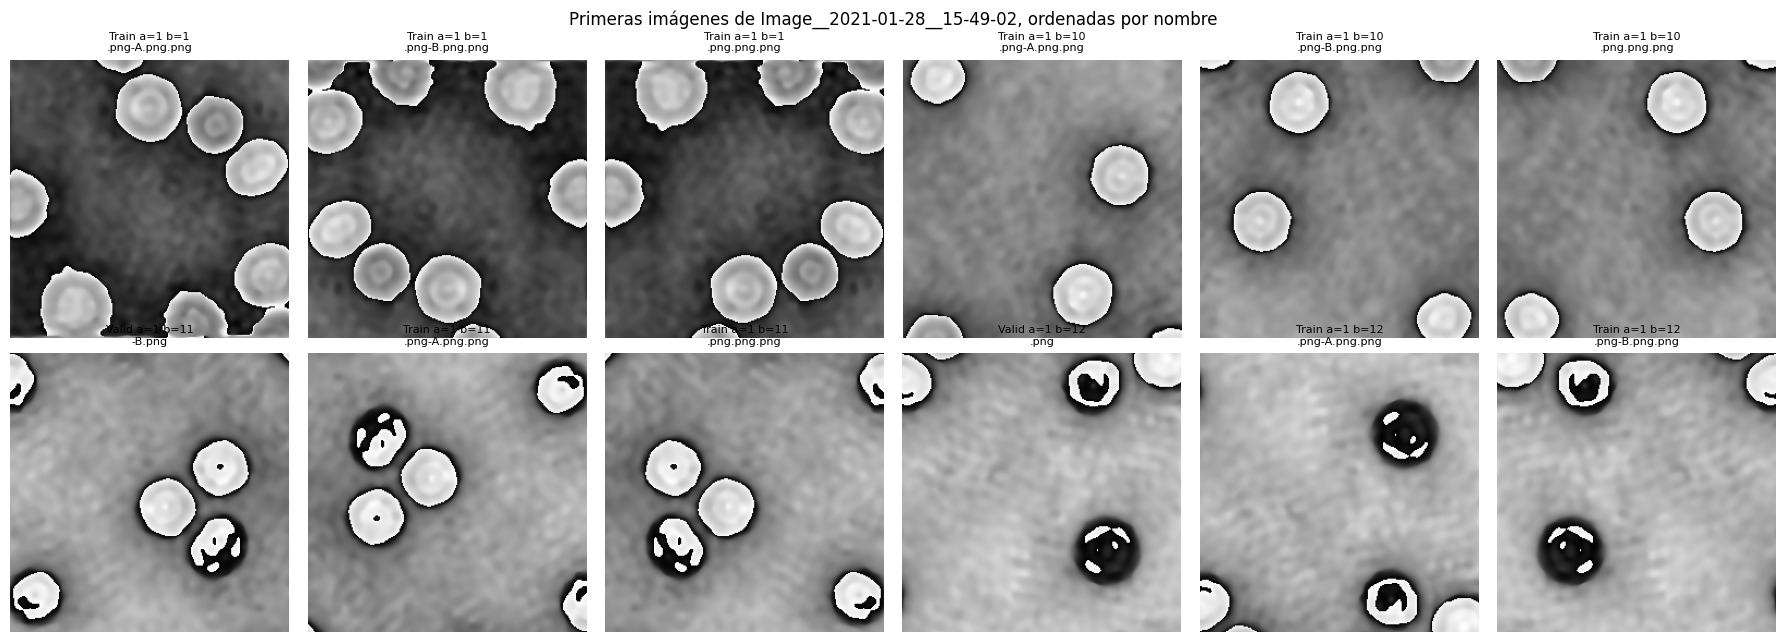

In [2]:
unmatched = diag_df[diag_df['source'].isna()]
print(f'Nombres que no siguen el patrón: {len(unmatched)}')
if len(unmatched):
    print(unmatched['file'].head(10).tolist())

named = diag_df.dropna(subset=['source']).copy()
named[['a', 'b']] = named[['a', 'b']].astype(int)
print(f"\nHologramas de origen (timestamp): {named['source'].nunique()}")
print(f"Valores del índice a: {sorted(named['a'].unique())}")
print(f"Índice b: {named['b'].min()}–{named['b'].max()} ({named['b'].nunique()} valores)")
print('\nSufijos (posible variante de aumentación):')
print(named['suffix'].value_counts().head(15))
print('\nImágenes por holograma de origen:')
print(named.groupby('source').size().describe().round(1))

example_source = named['source'].value_counts().index[0]
ex = named[named['source'] == example_source].sort_values('file').head(12)
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for ax in axes.ravel():
    ax.axis('off')
for ax, (_, row) in zip(axes.ravel(), ex.iterrows()):
    ax.imshow(Image.open(phase_path(row)), cmap='gray', vmin=0, vmax=255)
    ax.set_title(f"{row['split'][:5]} a={row['a']} b={row['b']}\n{row['suffix']}", fontsize=8)
plt.suptitle(f'Primeras imágenes de {example_source}, ordenadas por nombre')
plt.tight_layout()
plt.show()

### 0.2 Duplicados por simetría y fuga entre splits

La última tabla dice qué partes del nombre se mantienen dentro de un grupo de duplicados: la que es constante identifica el recorte, y la que cambia identifica la variante.

Imágenes: 36864 | recortes únicos (hasta simetría): 12288 | imágenes por recorte: 3.00

Tamaño de los grupos (nº de imágenes idénticas salvo rotación/flip):
3    12288
Name: grupos, dtype: int64

Recortes en Training y Validation a la vez: 5837 (47.5% de los recortes)
Imágenes de Validation con un duplicado en Training: 7088 de 7373
Hologramas de origen con imágenes en ambos splits: 192 de 192

Parte del nombre constante dentro de cada grupo de duplicados:
  source: 100.0% de los grupos
  a: 100.0% de los grupos
  b: 100.0% de los grupos
  suffix: 0.0% de los grupos


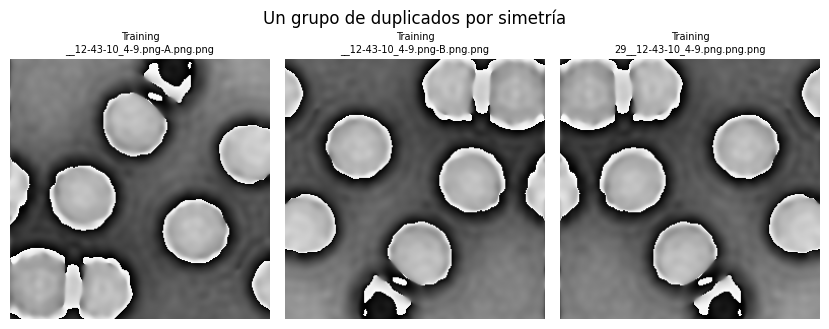

In [3]:
group_sizes = diag_df.groupby('hash').size()
n_groups = len(group_sizes)
print(f'Imágenes: {len(diag_df)} | recortes únicos (hasta simetría): {n_groups} | '
      f'imágenes por recorte: {len(diag_df) / n_groups:.2f}')
print('\nTamaño de los grupos (nº de imágenes idénticas salvo rotación/flip):')
print(group_sizes.value_counts().sort_index().rename('grupos'))

splits_per_group = diag_df.groupby('hash')['split'].nunique()
leaky = splits_per_group[splits_per_group > 1].index
val_df = diag_df[diag_df['split'] == 'Validation']
print(f'\nRecortes en Training y Validation a la vez: {len(leaky)} ({100 * len(leaky) / n_groups:.1f}% de los recortes)')
print(f"Imágenes de Validation con un duplicado en Training: {val_df['hash'].isin(leaky).sum()} de {len(val_df)}")

sources_per_split = named.groupby('source')['split'].nunique()
print(f'Hologramas de origen con imágenes en ambos splits: {(sources_per_split > 1).sum()} de {len(sources_per_split)}')

multi = named[named['hash'].map(group_sizes) > 1]
if len(multi):
    print('\nParte del nombre constante dentro de cada grupo de duplicados:')
    for col in ['source', 'a', 'b', 'suffix']:
        const = (multi.groupby('hash')[col].nunique() == 1).mean()
        print(f'  {col}: {100 * const:.1f}% de los grupos')

    example_hash = group_sizes.idxmax()
    ex = diag_df[diag_df['hash'] == example_hash].head(8)
    fig, axes = plt.subplots(1, len(ex), figsize=(2.8 * len(ex), 3.4), squeeze=False)
    for ax, (_, row) in zip(axes[0], ex.iterrows()):
        ax.imshow(Image.open(phase_path(row)), cmap='gray', vmin=0, vmax=255)
        ax.set_title(f"{row['split']}\n{row['file'][-28:]}", fontsize=7)
        ax.axis('off')
    plt.suptitle('Un grupo de duplicados por simetría')
    plt.tight_layout()
    plt.show()
else:
    print('\nNo hay duplicados exactos por simetría: las variantes no son rotaciones/flips exactos del mismo recorte '
          '(p. ej. hubo re-recorte o re-compresión). Revisar la figura de 0.1 para ver qué cambia entre nombres.')

### 0.3 Codificación de la fase

- Si casi todas las imágenes tienen `min = 0` y `max = 255` y el fondo varía mucho entre imágenes, los PNG se normalizaron **por imagen**: la fase absoluta en radianes se perdió y el delta de fase de #8 queda en niveles de gris.
- Si el fondo es estable y el mínimo y el máximo varían, la escala es **fija** y los niveles de gris son comparables entre imágenes.

Modos de imagen: {'L': 36864}
min = 0: 100.0% | max = 255: 100.0% | ambos: 100.0%

           min      max       p1      p99       bg
count  36864.0  36864.0  36864.0  36864.0  36864.0
mean       0.0    255.0     10.7    245.3    138.5
std        0.0      0.0      9.7      8.8     39.3
min        0.0    255.0      0.0    145.0     13.0
5%         0.0    255.0      2.0    230.0     78.0
50%        0.0    255.0      8.0    247.7    135.0
95%        0.0    255.0     28.0    254.0    209.0
max        0.0    255.0    187.0    255.0    245.0


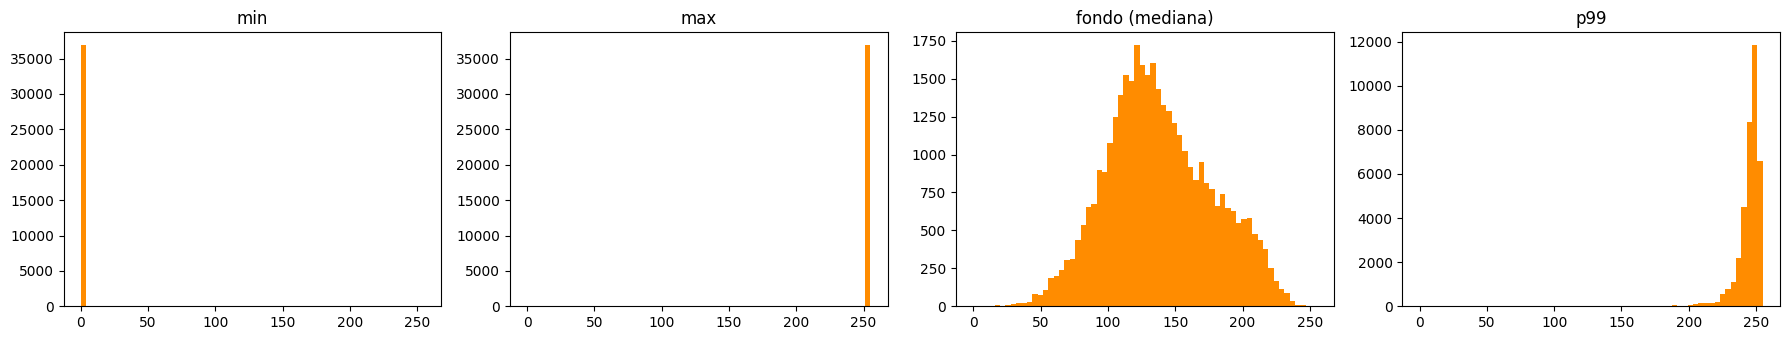

In [4]:
print(f"Modos de imagen: {diag_df['mode'].value_counts().to_dict()}")
print(f"min = 0: {100 * (diag_df['min'] == 0).mean():.1f}% | max = 255: {100 * (diag_df['max'] == 255).mean():.1f}% | "
      f"ambos: {100 * ((diag_df['min'] == 0) & (diag_df['max'] == 255)).mean():.1f}%")
print()
print(diag_df[['min', 'max', 'p1', 'p99', 'bg']].describe(percentiles=[0.05, 0.5, 0.95]).round(1))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, ['min', 'max', 'bg', 'p99']):
    ax.hist(diag_df[col], bins=64, range=(0, 255), color='darkorange')
    ax.set_title(col if col != 'bg' else 'fondo (mediana)')
plt.tight_layout()
plt.show()

### 0.4 Detector de manchas oscuras: actual vs. alternativa

En las grillas, en rojo está la máscara del criterio actual y en azul la de la alternativa. Lo que interesa es la primera grilla: si muestra células claras con bordes oscuros (imágenes buenas), el criterio actual está descartando de más.

Fracción marcada por cada criterio:
           cur_flag alt_flag
split                       
Training     72.0 %   64.9 %
Validation   71.3 %   64.3 %

alternativa  False   True    All
actual                          
False         8202   2163  10365
True          4767  21732  26499
All          12969  23895  36864


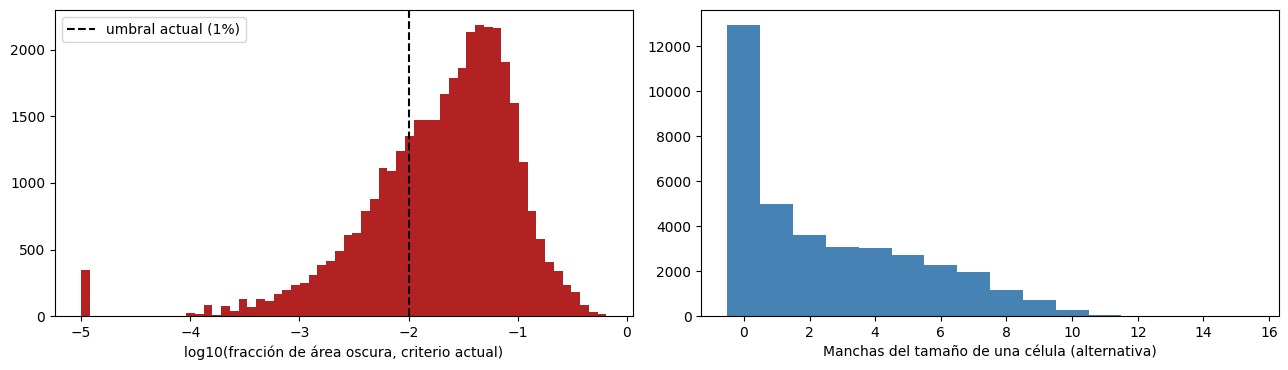

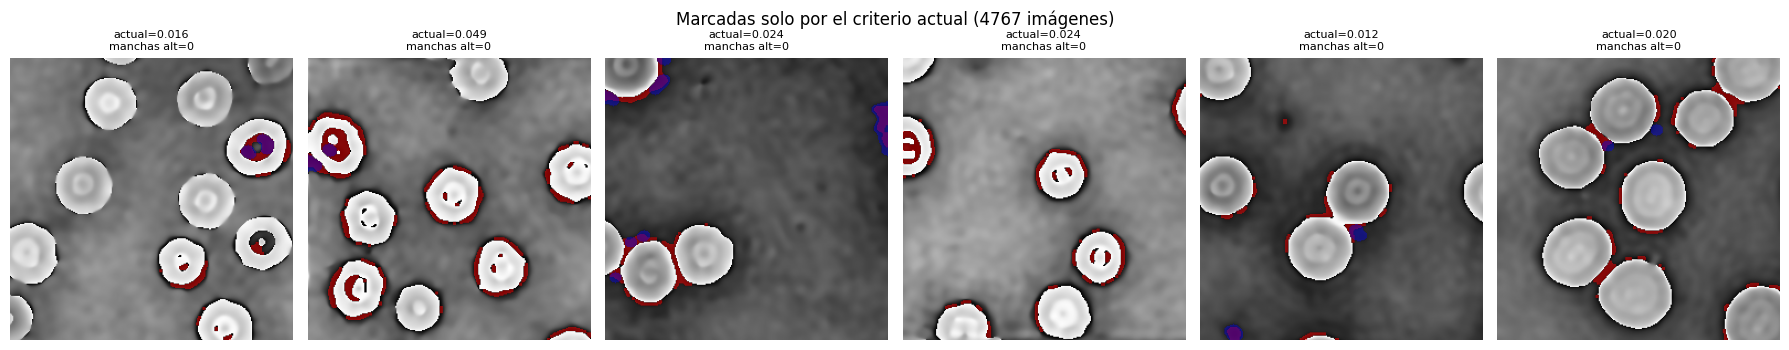

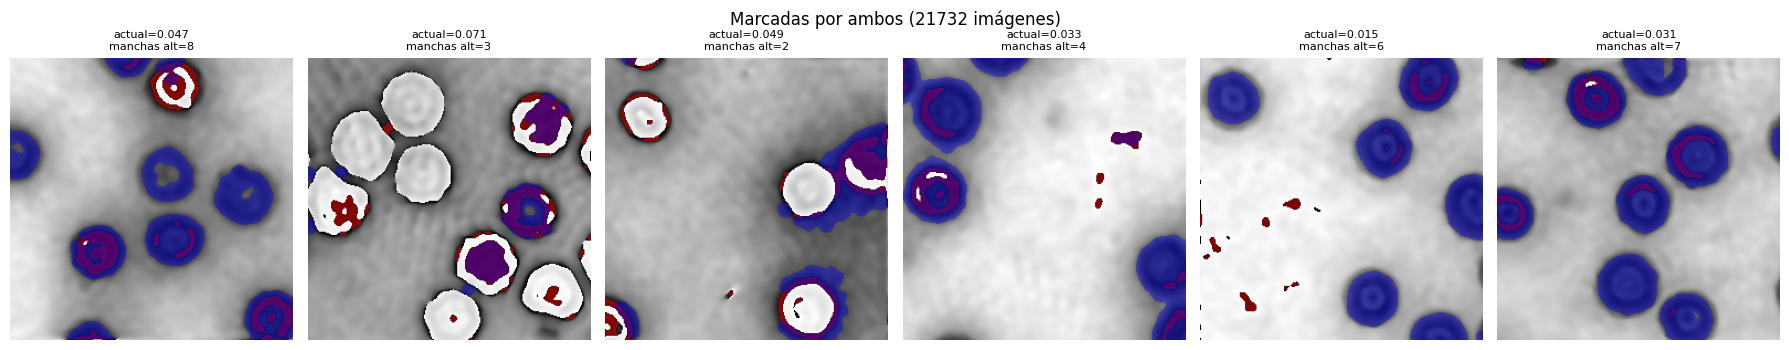

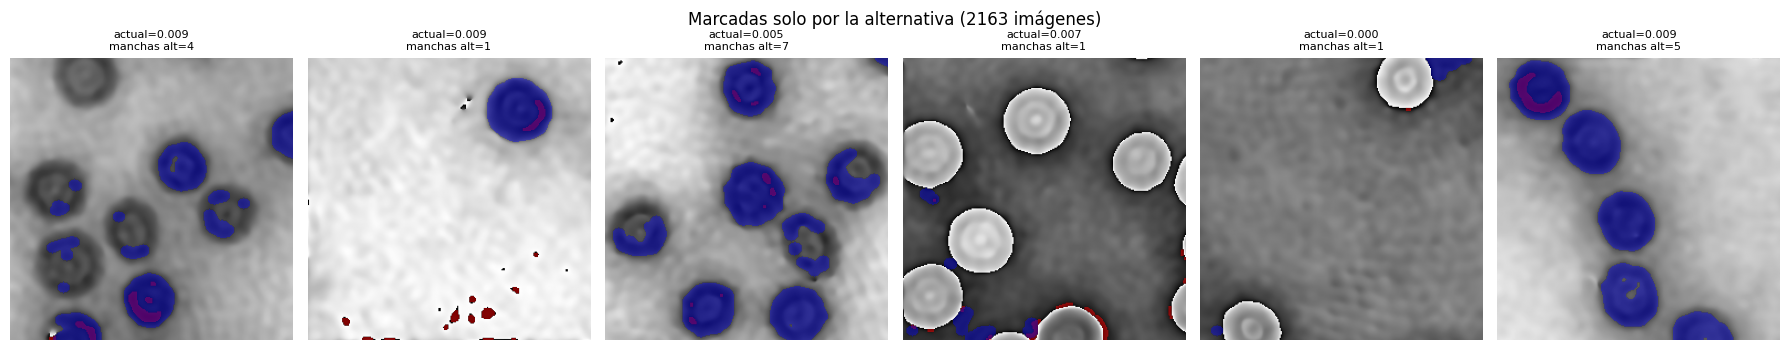

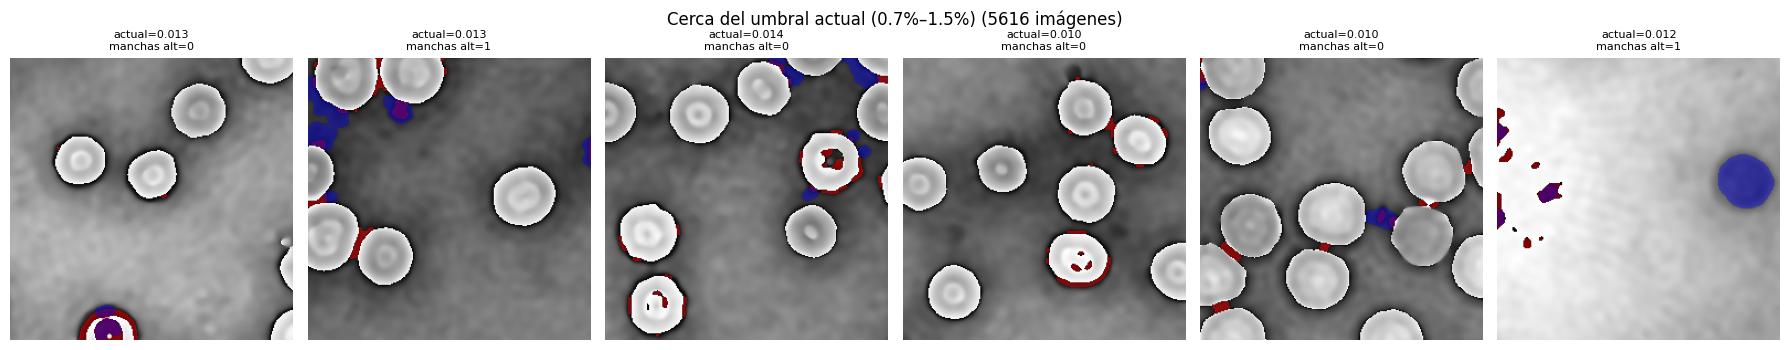

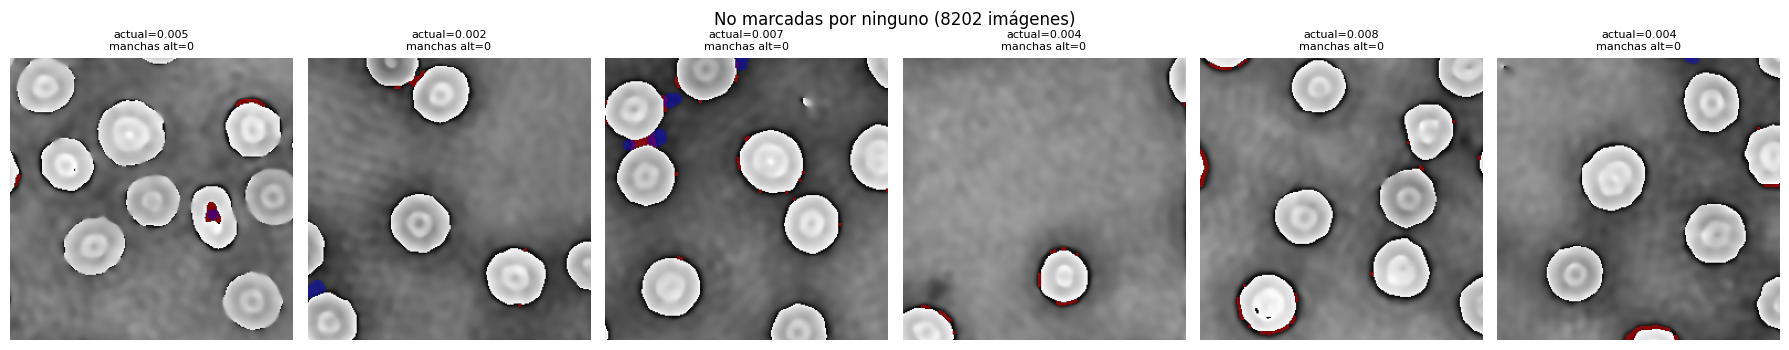

In [5]:
print('Fracción marcada por cada criterio:')
print(diag_df.groupby('split')[['cur_flag', 'alt_flag']].mean().mul(100).round(1).astype(str).add(' %'))
print()
print(pd.crosstab(diag_df['cur_flag'], diag_df['alt_flag'], rownames=['actual'], colnames=['alternativa'], margins=True))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(np.log10(diag_df['cur_ratio'] + 1e-5), bins=60, color='firebrick')
axes[0].axvline(np.log10(0.01), color='k', ls='--', label='umbral actual (1%)')
axes[0].set_xlabel('log10(fracción de área oscura, criterio actual)')
axes[0].legend()
axes[1].hist(diag_df['alt_blobs'], bins=np.arange(diag_df['alt_blobs'].max() + 2) - 0.5, color='steelblue')
axes[1].set_xlabel('Manchas del tamaño de una célula (alternativa)')
plt.tight_layout()
plt.show()


def show_detector_grid(df, title, n=6):
    if df.empty:
        print(f'{title}: sin casos')
        return
    sample = df.sample(min(n, len(df)), random_state=0)
    fig, axes = plt.subplots(1, len(sample), figsize=(3 * len(sample), 3.6), squeeze=False)
    for ax, (_, row) in zip(axes[0], sample.iterrows()):
        gray = np.array(Image.open(phase_path(row)).convert('L'))
        cur = current_dark_mask(gray) > 0
        alt = alt_dark_mask(gray, row['bg']) > 0
        ax.imshow(gray, cmap='gray', vmin=0, vmax=255)
        ax.imshow(np.ma.masked_where(~cur, cur), cmap='autumn', alpha=0.5)
        ax.imshow(np.ma.masked_where(~alt, alt), cmap='winter', alpha=0.4)
        ax.set_title(f"actual={row['cur_ratio']:.3f}\nmanchas alt={row['alt_blobs']}", fontsize=8)
        ax.axis('off')
    plt.suptitle(f'{title} ({len(df)} imágenes)')
    plt.tight_layout()
    plt.show()


show_detector_grid(diag_df[diag_df['cur_flag'] & ~diag_df['alt_flag']], 'Marcadas solo por el criterio actual')
show_detector_grid(diag_df[diag_df['cur_flag'] & diag_df['alt_flag']], 'Marcadas por ambos')
show_detector_grid(diag_df[~diag_df['cur_flag'] & diag_df['alt_flag']], 'Marcadas solo por la alternativa')
show_detector_grid(diag_df[diag_df['cur_ratio'].between(0.007, 0.015)], 'Cerca del umbral actual (0.7%–1.5%)')
show_detector_grid(diag_df[~diag_df['cur_flag'] & ~diag_df['alt_flag']], 'No marcadas por ninguno')

### 0.5 Verificación: ¿las manchas oscuras son un desfase del fondo?

Escala de los PNG especificada por el profesor: **0–255 ≡ [−π, π]** de forma fija, `φ = g / 255 · 2π − π`. Si es así, el dataset guarda la fase *envuelta* y los niveles de gris son comparables en radianes entre imágenes.

**Hipótesis:** el fondo de cada imagen tiene un desfase arbitrario (sin significado físico en DHM). Cuando la fase de una célula, sumada a ese desfase, pasa de +π, se envuelve a −π: la célula se ve oscura (una "vaquita") o con huecos negros. Si es así, mover el fondo a una referencia fija **en módulo 2π**, `φ' = wrap(φ − φ_fondo + φ_ref)`, lo arregla sin reescalar, así que se conservan las diferencias en radianes.

**Por qué la referencia no es 0:** las células retardan la luz, así que su Δφ respecto al fondo es positivo. Con el fondo en 0 solo caben Δφ < π. Con el fondo cerca de −π caben casi 2π, dejando un margen por debajo para los halos oscuros alrededor de las células. Se comparan varias referencias y se elige la que deja menos saltos.

El fondo se estima como la **moda circular** del histograma de fase: es la región plana más grande, y el histograma se suaviza con borde periódico para que un fondo cerca de ±π no quede partido en dos.

Tres pruebas:
1. **Visual:** imágenes marcadas por los detectores, antes y después de mover el fondo. Si las células oscuras pasan a ser claras, la hipótesis se confirma.
2. **Saltos de envolvimiento:** pares de píxeles vecinos con |Δg| > 128, es decir, un salto de fase mayor que π entre píxeles contiguos. Una fase bien muestreada no puede tenerlo, así que es un wrap. Si los saltos desaparecen al mover el fondo, eran por el desfase; los que quedan son wraps reales (Δφ fuera del rango que cabe).
3. **Fondo dentro de un holograma:** con escala fija, el fondo de los 64 recortes de un mismo holograma debería variar poco y de forma suave (desfase y aberración residual del holograma). Con min-max por recorte variaría sin patrón.

In [6]:
from scipy import ndimage as ndi

WRAP_JUMP_THRESH = 128  # niveles de gris entre píxeles vecinos (≡ π rad)
N_VERIF_SAMPLE = 2000
BG_REF_CANDIDATES = {'0': 0.0, '-π/2': -np.pi / 2, '-π+1': -np.pi + 1.0, '-π+0.5': -np.pi + 0.5}
BG_REF_SHOW = '-π+1'    # referencia usada en la prueba 1


def gray_to_phase(g):
    return g.astype(np.float32) / 255 * 2 * np.pi - np.pi


def phase_to_gray(phi):
    return np.round((phi + np.pi) / (2 * np.pi) * 255).astype(np.uint8)


def background_phase(phi):
    hist, edges = np.histogram(phi, bins=256, range=(-np.pi, np.pi))
    hist = ndi.gaussian_filter1d(hist.astype(float), sigma=3, mode='wrap')
    k = hist.argmax()
    return float((edges[k] + edges[k + 1]) / 2)


def move_background(phi, phi_bg, phi_ref):
    return np.angle(np.exp(1j * (phi - phi_bg + phi_ref)))


def wrap_jumps(g):
    g = g.astype(np.int16)
    mask = np.zeros(g.shape, dtype=bool)
    mask[:, :-1] |= np.abs(np.diff(g, axis=1)) > WRAP_JUMP_THRESH
    mask[:-1, :] |= np.abs(np.diff(g, axis=0)) > WRAP_JUMP_THRESH
    return mask


def load_phase(row):
    g = np.array(Image.open(phase_path(row)).convert('L'))
    phi = gray_to_phase(g)
    return g, phi, background_phase(phi)


# Una variante por recorte: las otras dos son el mismo recorte rotado/volteado (0.2)
originals = diag_df[diag_df['suffix'].isin(['.png.png.png', '.png'])].copy()
originals[['a', 'b']] = originals[['a', 'b']].astype(int)  # vienen como texto si diag_df no se cargó del CSV
originals['grupo'] = np.select(
    [originals['cur_flag'] & originals['alt_flag'], originals['cur_flag'], originals['alt_flag']],
    ['ambos', 'solo actual', 'solo alternativa'],
    default='ninguno',
)
print(f'Recortes únicos: {len(originals)}')
print(originals['grupo'].value_counts())

Recortes únicos: 12288
grupo
ambos               7244
ninguno             2734
solo actual         1589
solo alternativa     721
Name: count, dtype: int64


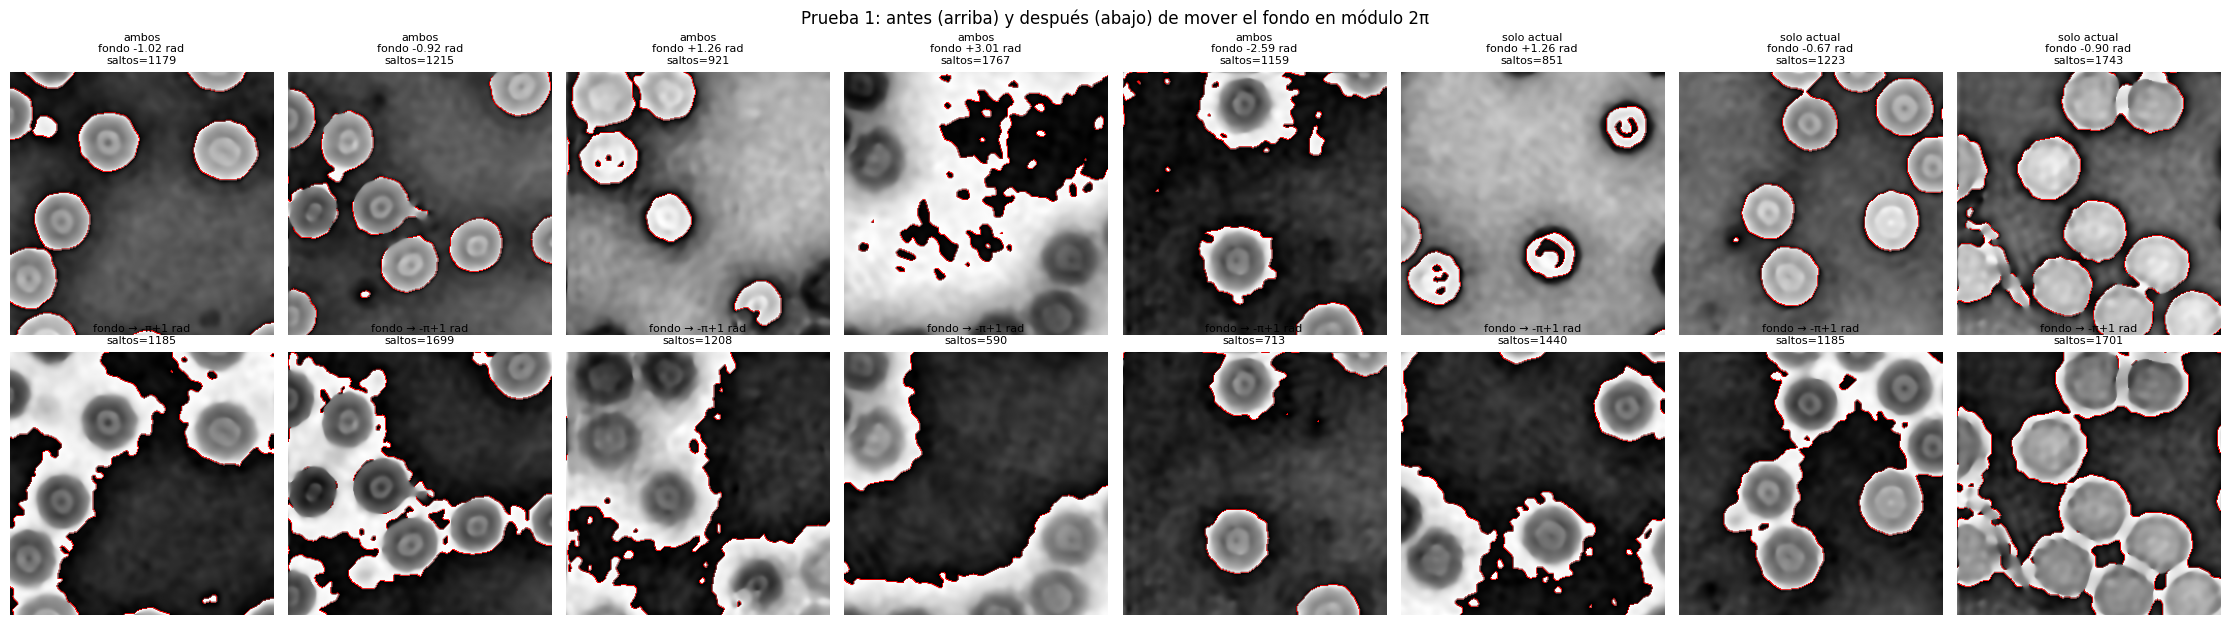

In [7]:
# Prueba 1: visual, antes (arriba) y después (abajo) de mover el fondo. En rojo, los saltos de wrap.
def pick(grupo, n):
    df = originals[originals['grupo'] == grupo]
    return df.sample(min(n, len(df)), random_state=0)


show = pd.concat([pick('ambos', 5), pick('solo actual', 3)])
phi_ref = BG_REF_CANDIDATES[BG_REF_SHOW]
fig, axes = plt.subplots(2, len(show), figsize=(2.8 * len(show), 6.4), squeeze=False)
for j, (_, row) in enumerate(show.iterrows()):
    g, phi, phi_bg = load_phase(row)
    g_moved = phase_to_gray(move_background(phi, phi_bg, phi_ref))
    for i, (img, title) in enumerate([(g, f"{row['grupo']}\nfondo {phi_bg:+.2f} rad"), (g_moved, f'fondo → {BG_REF_SHOW} rad')]):
        jumps = wrap_jumps(img)
        axes[i, j].imshow(img, cmap='gray', vmin=0, vmax=255)
        axes[i, j].imshow(np.ma.masked_where(~jumps, jumps), cmap='autumn', alpha=0.9)
        axes[i, j].set_title(f'{title}\nsaltos={jumps.sum()}', fontsize=8)
        axes[i, j].axis('off')
plt.suptitle('Prueba 1: antes (arriba) y después (abajo) de mover el fondo en módulo 2π')
plt.tight_layout()
plt.show()

verificación:   0%|          | 0/2000 [00:00<?, ?it/s]

% de recortes con al menos un salto de wrap, por grupo del detector y por referencia del fondo:
                  original      0   -π/2   -π+1  -π+0.5
grupo                                                  
ambos                 98.2   99.9  100.0  100.0   100.0
ninguno              100.0  100.0  100.0  100.0   100.0
solo actual          100.0  100.0  100.0  100.0   100.0
solo alternativa      96.2  100.0  100.0  100.0   100.0

Total:
original     98.7
0           100.0
-π/2        100.0
-π+1        100.0
-π+0.5      100.0

Mediana de píxeles con salto:
                  original       0    -π/2    -π+1  -π+0.5
grupo                                                     
ambos                794.0  1097.0  1141.0  1172.0  1227.5
ninguno              985.0   987.0  1060.0  1174.0  1305.0
solo actual         1220.5  1183.5  1206.5  1295.5  1387.0
solo alternativa     594.0   779.0   964.0   994.0  1209.0


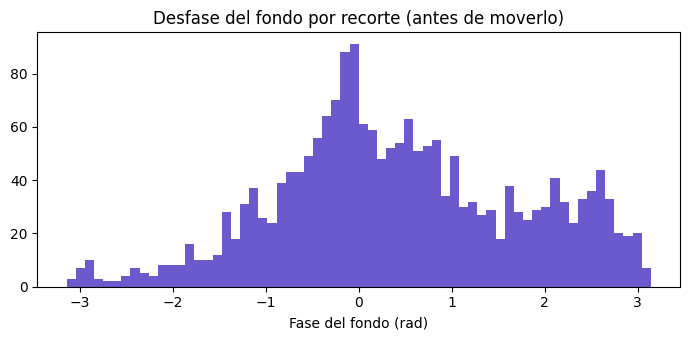

In [8]:
# Prueba 2: saltos de wrap en el original y con cada referencia, sobre una muestra de recortes únicos
verif_sample = originals.sample(min(N_VERIF_SAMPLE, len(originals)), random_state=0)
verif_rows = []
for _, row in tqdm(verif_sample.iterrows(), total=len(verif_sample), desc='verificación'):
    g, phi, phi_bg = load_phase(row)
    rec = {'file': row['file'], 'source': row['source'], 'a': row['a'], 'b': row['b'],
           'grupo': row['grupo'], 'bg_rad': phi_bg, 'original': int(wrap_jumps(g).sum())}
    for name, ref in BG_REF_CANDIDATES.items():
        rec[name] = int(wrap_jumps(phase_to_gray(move_background(phi, phi_bg, ref))).sum())
    verif_rows.append(rec)
verif_df = pd.DataFrame(verif_rows)

jump_cols = ['original', *BG_REF_CANDIDATES]
print('% de recortes con al menos un salto de wrap, por grupo del detector y por referencia del fondo:')
print((verif_df.groupby('grupo')[jump_cols].agg(lambda s: (s > 0).mean()) * 100).round(1))
print('\nTotal:')
print(((verif_df[jump_cols] > 0).mean() * 100).round(1).to_string())
print('\nMediana de píxeles con salto:')
print(verif_df.groupby('grupo')[jump_cols].median())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(verif_df['bg_rad'], bins=64, range=(-np.pi, np.pi), color='slateblue')
ax.set_xlabel('Fase del fondo (rad)')
ax.set_title('Desfase del fondo por recorte (antes de moverlo)')
plt.tight_layout()
plt.show()

Desviación circular del fondo dentro de un holograma (mediana): 0.73 rad
Desviación circular entre hologramas (de sus medias):          1.14 rad


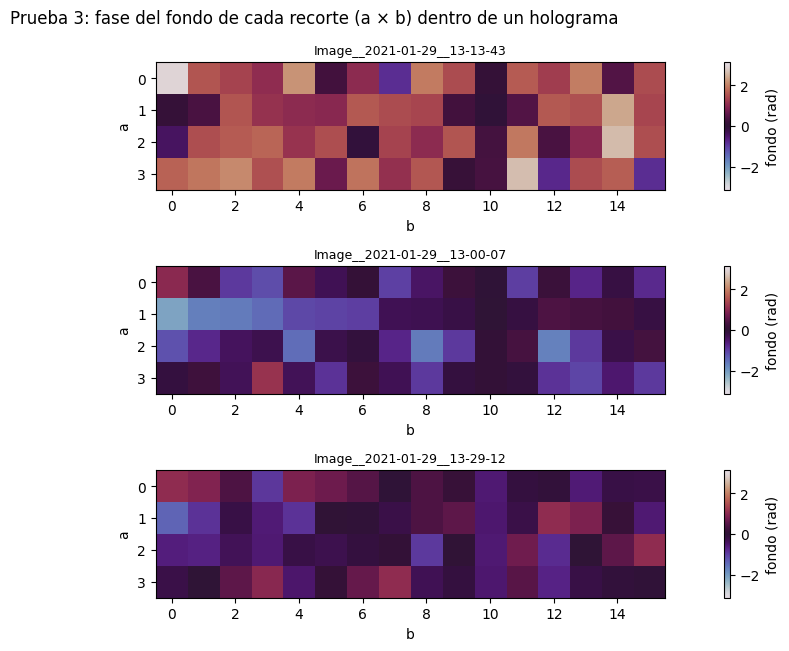

In [9]:
# Prueba 3: fondo dentro de un mismo holograma
def circ_mean(a):
    return float(np.angle(np.exp(1j * np.asarray(a)).mean()))


def circ_std(a):
    r = np.abs(np.exp(1j * np.asarray(a)).mean())
    return float(np.sqrt(-2 * np.log(max(r, 1e-12))))


by_source = verif_df.groupby('source')['bg_rad']
within = by_source.agg(circ_std)[by_source.size() >= 3]
between = circ_std(by_source.agg(circ_mean))
print(f'Desviación circular del fondo dentro de un holograma (mediana): {within.median():.2f} rad')
print(f'Desviación circular entre hologramas (de sus medias):          {between:.2f} rad')

heat_sources = originals['source'].drop_duplicates().sample(3, random_state=0)
fig, axes = plt.subplots(len(heat_sources), 1, figsize=(12, 2.2 * len(heat_sources)), squeeze=False)
for ax, source in zip(axes[:, 0], heat_sources):
    grid = np.full((int(originals['a'].max()), int(originals['b'].max())), np.nan)
    for _, row in originals[originals['source'] == source].iterrows():
        grid[int(row['a']) - 1, int(row['b']) - 1] = load_phase(row)[2]
    im = ax.imshow(grid, cmap='twilight', vmin=-np.pi, vmax=np.pi)
    ax.set_title(source, fontsize=9)
    ax.set_xlabel('b')
    ax.set_ylabel('a')
    fig.colorbar(im, ax=ax, label='fondo (rad)')
plt.suptitle('Prueba 3: fase del fondo de cada recorte (a × b) dentro de un holograma')
plt.tight_layout()
plt.show()

**Resultado de 0.5 (corrida del 2026-11-08): la hipótesis se descarta.** Los PNG no se comportan como una escala fija 0–255 ≡ [−π, π], sino como normalizados por recorte (min-max):
- El 100% de los recortes tiene mínimo 0 y máximo 255 exactos (0.3). Con escala fija, un recorte con el fondo en −1 rad y células de Δφ ≈ 2 rad no llegaría a 255.
- Mover el fondo empeora todas las imágenes (prueba 1): dentro de un recorte el "fondo" varía mucho más de 1 rad.
- Hay saltos > 128 niveles en el borde de cada célula, incluso en las imágenes buenas (prueba 2): es el halo oscuro llevado a 0 junto a la célula llevada a 255, típico de un estiramiento min-max.
- El fondo varía casi tanto dentro de un holograma (0,73 rad) como entre hologramas (1,14 rad), sin patrón espacial (prueba 3).

Probablemente la reconstrucción estaba en [−π, π] (`np.angle`) y al exportar cada recorte se estiró con su propio mínimo y máximo: en los recortes con fase envuelta coincide casi con la escala fija, en los demás no. Pendiente de confirmar con el profesor.

**Consecuencia:** los niveles de gris son relativos a cada recorte. No se renormaliza (no hay una proporción en radianes que conservar); en el DataLoader se mapea 0–255 → [−1, 1]. El delta de fase de #8 queda en unidades relativas, no en radianes.

## 1. Limpieza

Decisiones tomadas a partir del diagnóstico:
1. **Una variante por recorte.** Cada recorte aparece 3 veces (original, `-A`, `-B`), rotado o volteado (0.2). Se conserva la variante sin sufijo; la aumentación se hace al azar en el DataLoader (`random_dihedral` de `03-limpieza-malaria.ipynb`).
2. **Filtro de artefactos de fase.** Se conservan solo los recortes que no marca ni el criterio actual ni la alternativa (0.4). Es conservador: el criterio actual también descarta imágenes buenas con muchos bordes oscuros, así que más abajo se mide si eso sesga el número de células por recorte.
3. **Split 80/20 por holograma de origen.** El del paper tiene fuga: el 96% de `Validation` está repetido en `Training` (0.2), y los recortes de un mismo holograma se solapan.
4. **Sin renormalización** (ver el resultado de 0.5).

Requiere haber corrido las secciones 0 a 0.4 (`diag_df`, `phase_path` y `show_detector_grid`); la 0.5 no hace falta.

In [10]:
import json
import random
import shutil

from scipy import ndimage as ndi
from skimage import filters, measure

SEED = 123
VAL_FRAC = 0.2
ORIGINAL_SUFFIXES = {'.png.png.png', '.png'}
OUT_DIR = Path('/content/data/processed/rbc_fases_processed')
DRIVE_OUT_DIR = Path('/content/drive/MyDrive/dl-qpi/data/processed')
ZIP_BASENAME = 'rbc_fases_processed'

crops = diag_df[diag_df['suffix'].isin(ORIGINAL_SUFFIXES)].copy()
crops[['a', 'b']] = crops[['a', 'b']].astype(int)
assert crops['hash'].is_unique and len(crops) == diag_df['hash'].nunique(), \
    'Se esperaba exactamente una variante sin sufijo por recorte'

crops['motivo'] = np.select(
    [crops['cur_flag'] & crops['alt_flag'], crops['cur_flag'], crops['alt_flag']],
    ['artefacto_ambos', 'artefacto_actual', 'artefacto_alternativa'],
    default='mantenido',
)

sources = sorted(crops['source'].unique())
random.Random(SEED).shuffle(sources)
n_val = round(len(sources) * VAL_FRAC)
split_by_source = {s: 'Validation' if i < n_val else 'Training' for i, s in enumerate(sources)}
crops['new_split'] = crops['source'].map(split_by_source)
kept = crops[crops['motivo'] == 'mantenido'].copy()

print(f'Imágenes en el dataset: {len(diag_df)}')
print(f'  variantes duplicadas descartadas: {len(diag_df) - len(crops)}')
print(f'Recortes únicos: {len(crops)}')
for motivo, n in crops['motivo'].value_counts().items():
    print(f'  {motivo}: {n} ({100 * n / len(crops):.1f}%)')
print()
print(kept.groupby('new_split').agg(recortes=('file', 'size'), hologramas=('source', 'nunique')))

Imágenes en el dataset: 36864
  variantes duplicadas descartadas: 24576
Recortes únicos: 12288
  artefacto_ambos: 7244 (59.0%)
  mantenido: 2734 (22.2%)
  artefacto_actual: 1589 (12.9%)
  artefacto_alternativa: 721 (5.9%)

            recortes  hologramas
new_split                       
Training        2292         102
Validation       442          27


### 1.1 Células por recorte y sesgo del filtro

Segmentación simple (Otsu sobre la imagen suavizada, apertura y relleno de huecos). Se cuentan también las células cortadas por el borde si conservan al menos `MIN_CELL_AREA` px, para que el conteo sea comparable con el de malaria, que cuenta toda caja con el centro dentro del parche. Las células pegadas se segmentan como una sola, así que el conteo es una cota inferior.

Se compara el número de células de los recortes mantenidos con una muestra de los descartados solo por el criterio actual (en su mayoría imágenes buenas con muchos bordes oscuros, ver 0.4) y, si `03-limpieza-malaria.ipynb` ya dejó su manifiesto, con los parches de malaria.

mantenidos:   0%|          | 0/2734 [00:00<?, ?it/s]

descartados (actual):   0%|          | 0/1000 [00:00<?, ?it/s]

No está /content/data/processed/malaria_processed/manifest.csv: se omite la comparación con malaria
       fase mantenidos  fase descartados solo por el actual
count           2734.0                               1000.0
mean               5.9                                  6.6
std                2.3                                  2.2
min                0.0                                  1.0
25%                4.0                                  5.0
50%                6.0                                  7.0
75%                7.0                                  8.0
max               13.0                                 16.0


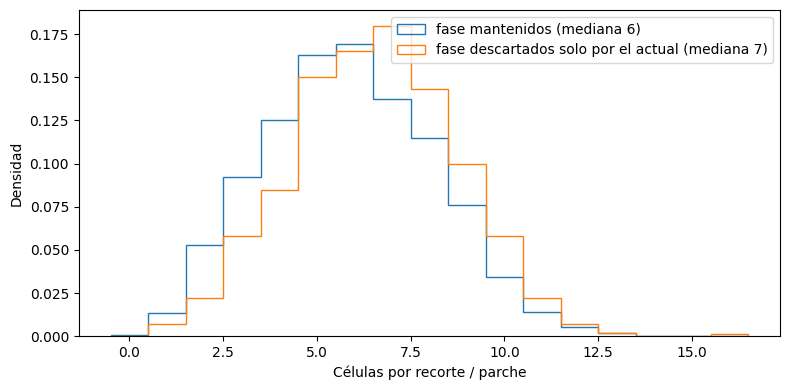

In [11]:
MIN_CELL_AREA = 800        # px; ~40% de un eritrocito de ~50 px de diámetro
N_BIAS_SAMPLE = 1000
MALARIA_MANIFEST = Path('/content/data/processed/malaria_processed/manifest.csv')


def segment_cells(gray):
    smooth = filters.gaussian(gray.astype(np.float32), sigma=2, preserve_range=True)
    mask = smooth > filters.threshold_otsu(smooth)
    mask = ndi.binary_opening(mask, structure=np.ones((5, 5), dtype=bool))
    mask = ndi.binary_fill_holes(mask)
    return [r.bbox for r in measure.regionprops(measure.label(mask)) if r.area >= MIN_CELL_AREA]


def cell_boxes(df, desc):
    return [segment_cells(np.array(Image.open(phase_path(row)).convert('L')))
            for _, row in tqdm(df.iterrows(), total=len(df), desc=desc)]


kept['cell_boxes'] = cell_boxes(kept, 'mantenidos')
kept['n_cells'] = kept['cell_boxes'].map(len)

flagged_current = crops[crops['motivo'] == 'artefacto_actual']
bias_sample = flagged_current.sample(min(N_BIAS_SAMPLE, len(flagged_current)), random_state=SEED)
bias_n_cells = pd.Series([len(b) for b in cell_boxes(bias_sample, 'descartados (actual)')], dtype=float)

compare = {'fase mantenidos': kept['n_cells'], 'fase descartados solo por el actual': bias_n_cells}
if MALARIA_MANIFEST.exists():
    compare['malaria (parches)'] = pd.read_csv(MALARIA_MANIFEST)['n_cells']
else:
    print(f'No está {MALARIA_MANIFEST}: se omite la comparación con malaria')

print(pd.DataFrame({k: v.describe(percentiles=[0.25, 0.5, 0.75]) for k, v in compare.items()}).round(1))

fig, ax = plt.subplots(figsize=(8, 4))
max_cells = int(pd.concat(compare.values()).max())
bins = np.arange(max_cells + 2) - 0.5
for label, values in compare.items():
    ax.hist(values, bins=bins, density=True, histtype='step', lw=2, label=f'{label} (mediana {values.median():.0f})')
ax.set_xlabel('Células por recorte / parche')
ax.set_ylabel('Densidad')
ax.legend()
plt.tight_layout()
plt.show()

### 1.2 Ejemplos

Recortes mantenidos con las células segmentadas, y ejemplos descartados por cada criterio (en rojo la máscara del criterio actual, en azul la de la alternativa).

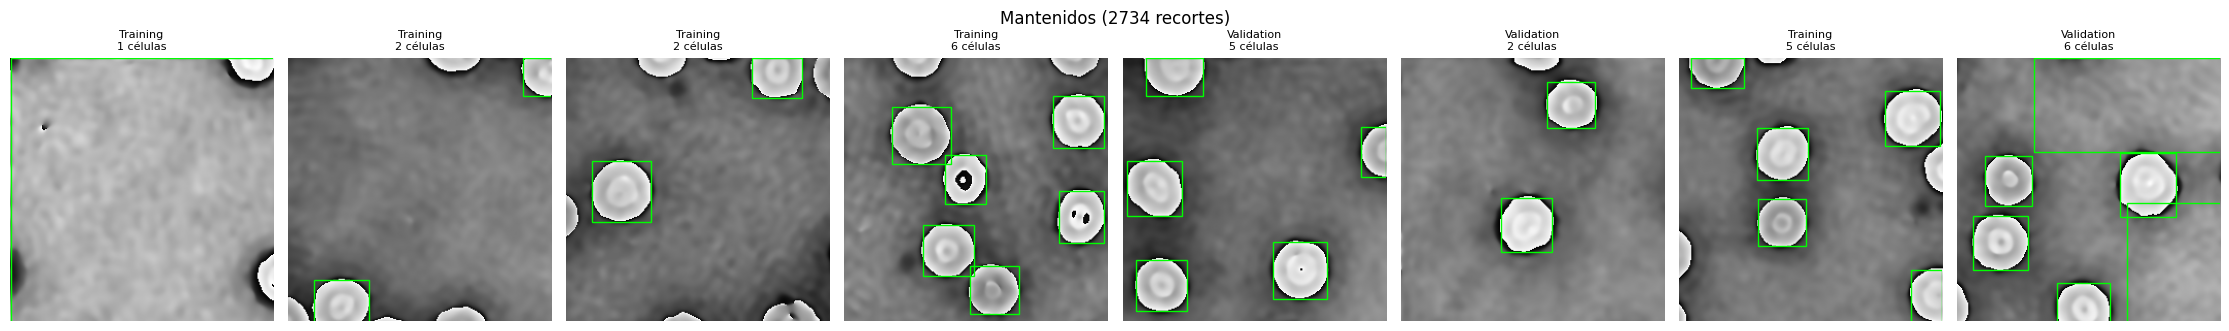

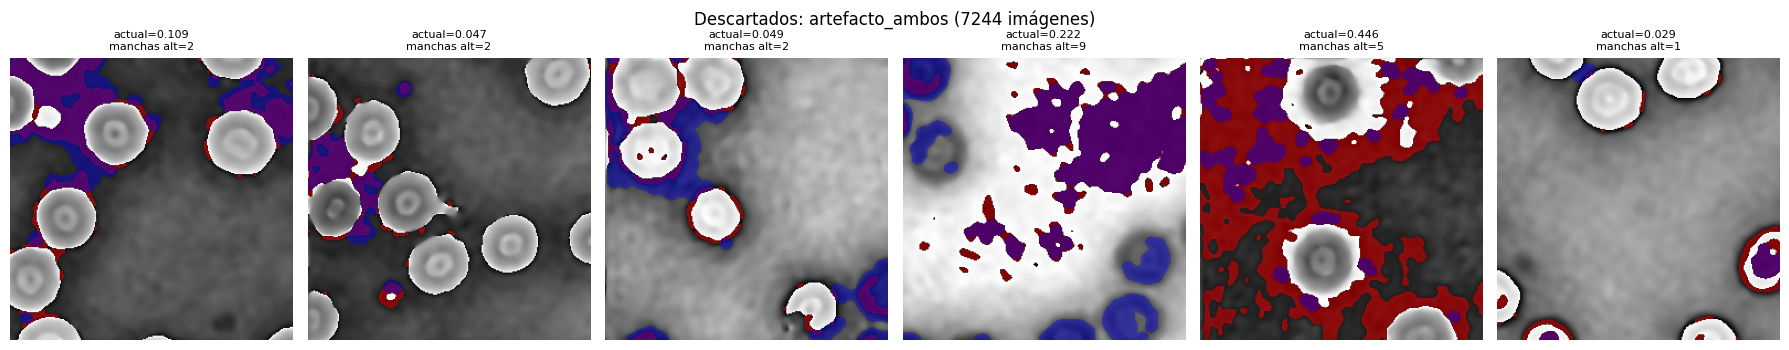

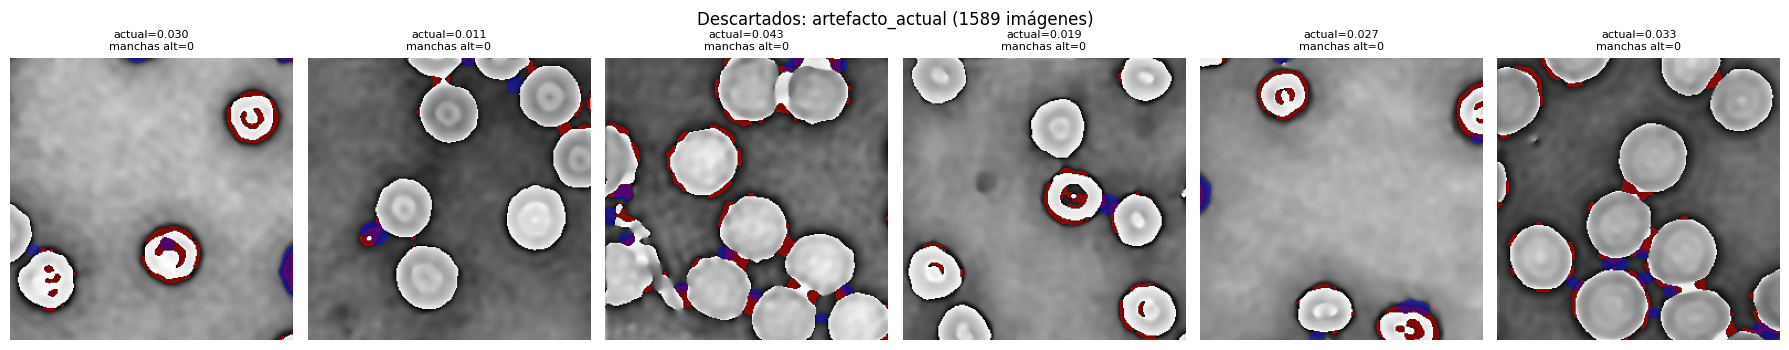

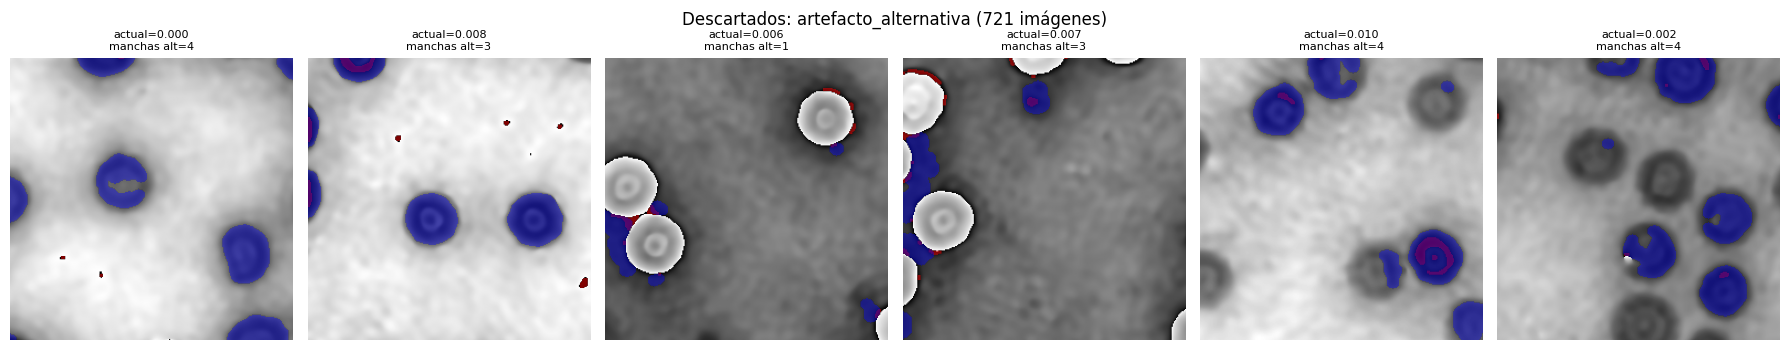

In [12]:
sample_kept = kept.sample(min(8, len(kept)), random_state=SEED)
fig, axes = plt.subplots(1, max(len(sample_kept), 1), figsize=(2.8 * max(len(sample_kept), 1), 3.4), squeeze=False)
for ax, (_, row) in zip(axes[0], sample_kept.iterrows()):
    ax.imshow(Image.open(phase_path(row)), cmap='gray', vmin=0, vmax=255)
    for r0, c0, r1, c1 in row['cell_boxes']:
        ax.add_patch(plt.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, edgecolor='lime', lw=1))
    ax.set_title(f"{row['new_split']}\n{row['n_cells']} células", fontsize=8)
for ax in axes[0]:
    ax.axis('off')
plt.suptitle(f'Mantenidos ({len(kept)} recortes)')
plt.tight_layout()
plt.show()

for motivo in ['artefacto_ambos', 'artefacto_actual', 'artefacto_alternativa']:
    show_detector_grid(crops[crops['motivo'] == motivo], f'Descartados: {motivo}')

### 1.3 Guardar

Se copian los PNG mantenidos sin recodificar a `OUT_DIR/<split>/`, con nombre `<holograma>_<a>-<b>.png`, junto con:
- `manifest.csv`: un recorte por fila, con el holograma de origen, los índices `a`/`b`, el split y el nombre originales del paper, el fondo (mediana de gris), el nº de células y sus cajas `[r0, c0, r1, c1]` (JSON). Las cajas sirven para el perfil de fase de #8; las que tocan el borde del recorte son células cortadas.
- `params.json`: los parámetros y conteos con los que se generó la salida.

Antes de escribir se borra lo que generó una corrida anterior de este notebook.

In [13]:
for split in PHASE_SPLITS:
    shutil.rmtree(OUT_DIR / split, ignore_errors=True)
    (OUT_DIR / split).mkdir(parents=True)

manifest_rows = []
for _, row in tqdm(kept.iterrows(), total=len(kept), desc='guardando'):
    name = f"{row['source']}_{row['a']}-{row['b']}.png"
    shutil.copy2(phase_path(row), OUT_DIR / row['new_split'] / name)
    manifest_rows.append({
        'file': f"{row['new_split']}/{name}",
        'split': row['new_split'],
        'source': row['source'],
        'a': row['a'],
        'b': row['b'],
        'split_paper': row['split'],
        'file_paper': row['file'],
        'bg_gray': row['bg'],
        'n_cells': row['n_cells'],
        'cell_boxes': json.dumps([[int(v) for v in box] for box in row['cell_boxes']]),
    })

manifest_df = pd.DataFrame(manifest_rows)
manifest_df.to_csv(OUT_DIR / 'manifest.csv', index=False)

params = {
    'seed': SEED,
    'val_frac': VAL_FRAC,
    'variante_conservada': sorted(ORIGINAL_SUFFIXES),
    'filtro': 'se conservan los recortes no marcados por el criterio actual ni por la alternativa (sección 0.4)',
    'dark_thresh': DARK_THRESH,
    'alt_dark_frac_of_bg': ALT_DARK_FRAC_OF_BG,
    'alt_open_radius': ALT_OPEN_RADIUS,
    'alt_min_blob_area': ALT_MIN_BLOB_AREA,
    'min_cell_area': MIN_CELL_AREA,
    'escala': 'niveles de gris relativos a cada recorte (min-max); mapear 0-255 a [-1, 1] en el DataLoader',
    'imagenes_dataset': len(diag_df),
    'recortes_unicos': len(crops),
    'conteo_por_motivo': crops['motivo'].value_counts().to_dict(),
    'hologramas_por_split': kept.groupby('new_split')['source'].nunique().to_dict(),
    'recortes_por_split': kept['new_split'].value_counts().to_dict(),
}
with open(OUT_DIR / 'params.json', 'w') as f:
    json.dump(params, f, indent=2, ensure_ascii=False)

print(manifest_df.groupby('split').agg(recortes=('file', 'size'), hologramas=('source', 'nunique'), celulas_mediana=('n_cells', 'median')))
print(f'\nSalida: {OUT_DIR}')

guardando:   0%|          | 0/2734 [00:00<?, ?it/s]

            recortes  hologramas  celulas_mediana
split                                            
Training        2292         102              6.0
Validation       442          27              6.0

Salida: /content/data/processed/rbc_fases_processed


## 2. Comprimir y copiar a Drive

In [14]:
if not Path('/content/drive/MyDrive').is_dir():
    from google.colab import drive
    drive.mount('/content/drive')

zip_path = Path(shutil.make_archive(str(OUT_DIR.parent / ZIP_BASENAME), 'zip', root_dir=OUT_DIR))
DRIVE_OUT_DIR.mkdir(parents=True, exist_ok=True)
drive_zip = Path(shutil.copy2(zip_path, DRIVE_OUT_DIR / zip_path.name))
print(f'{zip_path} ({zip_path.stat().st_size / 1024 ** 2:.1f} MB) -> {drive_zip}')

/content/data/processed/rbc_fases_processed.zip (58.6 MB) -> /content/drive/MyDrive/dl-qpi/data/processed/rbc_fases_processed.zip
